In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv(r"pakistan_tech_jobs_final.csv")

In [3]:
df.drop('job_description',inplace=True,axis=1)

In [4]:
df.isna().sum()
df['education']=df['education'].fillna(df['education'].mode()[0])

In [5]:
#K means to cluster job categories
#Linear to predict min max salries 
#logistic to predict job_title
#KNN to predict five related jobs
#firstly preprocessing
df['job_title']=df['job_title'].fillna(df['job_title'].mode()[0])
df.isna().sum()
df.duplicated().sum()#No Duplicates

np.int64(0)

In [6]:
#Predicting min and max salaries
cols_for_min=['experience_min','city','job_category','work_mode','education']
cols_for_max=['experience_max','city','job_category','work_mode','education']

In [7]:
df_lr=df[cols_for_min]

In [8]:
df_lr_max=df[cols_for_max]

In [9]:
df_lr.head()

,experience_min,city,job_category,work_mode,education
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's
1,2.0,Lahore,Web Development,On-site,Bachelor's
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's
3,2.0,Karachi,Web Development,On-site,Bachelor's
4,0.0,Karachi,Mobile Development,Remote,Bachelor's


<Axes: xlabel='experience_min'>

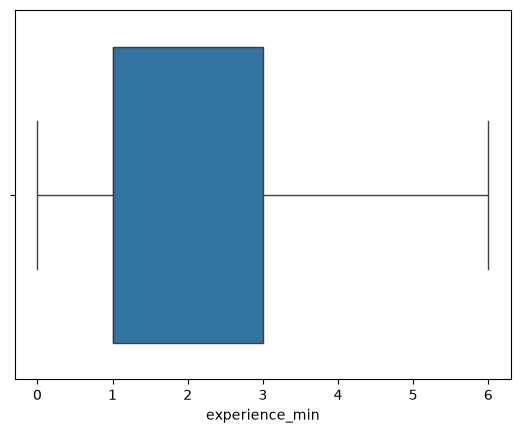

In [10]:
sns.boxplot(data=df_lr,x='experience_min')

In [11]:
top_cities = ['Karachi', 'Lahore', 'Islamabad', 'Rawalpindi']
df_lr['city_tier'] = df_lr['city'].apply(lambda x: x if x in top_cities else 'Other')
df_lr_max['city_tier'] = df_lr_max['city'].apply(lambda x: x if x in top_cities else 'Other')

In [12]:
df_lr['education']=df_lr['education'].replace({"Master's":1,"Bachelor's":0}).astype(int)
df_lr_max['education']=df_lr_max['education'].replace({"Master's":1,"Bachelor's":0}).astype(int)
df_lr_max=pd.get_dummies(df_lr_max,drop_first=True,columns=['work_mode','city_tier','job_category'],dtype=int)
df_lr=pd.get_dummies(df_lr,drop_first=True,columns=['work_mode','city_tier','job_category'],dtype=int)

In [13]:
df_lr.head()
df_lr.drop('city',inplace=True,axis=1)
df_lr_max.drop('city',inplace=True,axis=1)

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
scaler=StandardScaler()

In [15]:
from sklearn.metrics import r2_score, mean_absolute_error

In [16]:
X_train,X_test,y_train,y_test=train_test_split(df_lr,df['salary_min'],test_size=0.25,random_state=42)
X_train['experience_min']=scaler.fit_transform(X_train[['experience_min']])
X_test['experience_min']=scaler.transform(X_test[['experience_min']])
model2=LinearRegression()
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)
r2=r2_score(y_test,y_pred)
print(f"R2:{r2}")

R2:0.7332683225740553


In [17]:
X_train,X_test,y_train,y_test=train_test_split(df_lr_max,df['salary_max'],test_size=0.25,random_state=42)
X_train['experience_max']=scaler.fit_transform(X_train[['experience_max']])
X_test['experience_max']=scaler.transform(X_test[['experience_max']])
model4=LinearRegression()
model4.fit(X_train,y_train)
y_pred=model4.predict(X_test)
r2=r2_score(y_test,y_pred)
print(f"R2:{r2}")

R2:0.7178762846426073


In [18]:
cols_for_sal=['experience_min','city','job_category','work_mode','education','experience_max','salary_min','salary_max']
reg_df=df[cols_for_sal]

In [19]:
scaling_cols=['experience_max','experience_min','avg_experience']

In [20]:
reg_df.head()

,experience_min,city,job_category,work_mode,education,experience_max,salary_min,salary_max
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,560000.0,840000.0
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,80000.0,110000.0
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,60000.0,100000.0
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,50000.0,60000.0
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,40000.0,59998.0


In [21]:
reg_df['avg_experience']=((reg_df['experience_min']+reg_df['experience_max'])/2)
reg_df['avg_sal']=((reg_df['salary_min']+reg_df['salary_max'])/2)
reg_df.head()

,experience_min,city,job_category,work_mode,education,experience_max,salary_min,salary_max,avg_experience,avg_sal
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,560000.0,840000.0,6.5,700000.0
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,80000.0,110000.0,3.5,95000.0
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,60000.0,100000.0,3.5,80000.0
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,50000.0,60000.0,3.5,55000.0
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,40000.0,59998.0,1.0,49999.0


In [22]:
top_cities = ['Karachi', 'Lahore', 'Islamabad', 'Rawalpindi']
reg_df['city_tier'] = reg_df['city'].apply(lambda x: x if x in top_cities else 'Other')

In [23]:
reg_df=pd.get_dummies(reg_df,drop_first=True,columns=['work_mode','city_tier','job_category'],dtype=int)
reg_df['education']=reg_df['education'].replace({"Master's":1,"Bachelor's":0}).astype(int)

In [24]:
reg_df.drop('city',axis=1,inplace=True)
reg_df.head()

,experience_min,education,experience_max,salary_min,salary_max,avg_experience,avg_sal,work_mode_On-site,work_mode_Remote,city_tier_Karachi,city_tier_Lahore,city_tier_Other,city_tier_Rawalpindi,job_category_Cybersecurity,job_category_Data Science / AI / ML,job_category_Mobile Development,job_category_QA / Testing,job_category_Software Development,job_category_Web Development
0,5.0,0,8.0,560000.0,840000.0,6.5,700000.0,0,1,1,0,0,0,0,1,0,0,0,0
1,2.0,0,5.0,80000.0,110000.0,3.5,95000.0,1,0,0,1,0,0,0,0,0,0,0,1
2,2.0,0,5.0,60000.0,100000.0,3.5,80000.0,1,0,0,1,0,0,0,1,0,0,0,0
3,2.0,0,5.0,50000.0,60000.0,3.5,55000.0,1,0,1,0,0,0,0,0,0,0,0,1
4,0.0,0,2.0,40000.0,59998.0,1.0,49999.0,0,1,1,0,0,0,0,0,1,0,0,0


In [25]:
X=reg_df.drop(columns=['avg_sal', 'salary_min', 'salary_max'],)
y=reg_df['avg_sal']

In [26]:
x_scale=StandardScaler()
y_scale=StandardScaler()

In [27]:
y_train.head()

1043    145000.0
1813    210000.0
123     520000.0
572     220000.0
394     135000.0
Name: salary_max, dtype: float64

In [28]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
X_train[scaling_cols]=x_scale.fit_transform(X_train[scaling_cols])
X_test[scaling_cols]=x_scale.transform(X_test[scaling_cols])

In [29]:
model5=LinearRegression()
model5.fit(X_train,y_train)
y_pred=model5.predict(X_test)
y_pred_train=model5.predict(X_train)
r2=r2_score(y_test,y_pred)
print(f"R2:{r2}")
print(r2_score(y_train,y_pred_train))

R2:0.7346378059328605
0.7186113075969647
